# Praktikum Data Mining — Association Rule Mining (Market Basket Analysis)

**Kelompok 7 Data Mining**

**Anggota:** Lutfiah Sahira **(24343039)**,
            Imam Atthahira **(24343037)** ,
            Rangga Dharma Putra **(24343045)**.
**Mata kuliah:** Data Mining· **Dosen pengampu:** Dr. Yeka Hendriyani, S.Kom., M.Kom.
**Program Studi Informatika, Departemen Teknik Elektronika, Fakultas Teknik, Universitas Negeri Padang**

## 4.1 Persiapan Data Transaksi

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlxtend
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

os.makedirs('figs', exist_ok=True)
NAVY, GOLD, RED = '#1E2761', '#F4D35E', '#C0392B'

print('pandas  :', pd.__version__)
print('numpy   :', np.__version__)
print('mlxtend :', mlxtend.__version__)

pandas  : 3.0.6
numpy   : 2.5.4
mlxtend : 0.25.0


**Pengamatan.** Seluruh pustaka berhasil dimuat. Lingkungan eksekusi memakai mlxtend 0,25.0, pandas 3.0.6, dan numpy 2.5.4. Folder figs dibuat untuk menyimpan seluruh grafik yang dihasilkan, sedangkan warna navy dan emas didefinisikan sekali agar tampilan grafik konsisten.

In [2]:
# Membaca dataset transaksi (kolom Items berisi daftar item dipisahkan koma)
raw = pd.read_csv('transactions_arm_praktikum.csv')
transactions = [[i.strip() for i in s.split(',')] for s in raw['Items']]

print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


**Pengamatan.** Berkas CSV memiliki dua kolom, yaitu TID dan Items. Kolom Items berisi string yang dipisahkan koma, sehingga setiap barisnya dipecah menjadi sebuah list item. Hasilnya adalah 60 transaksi. Lima transaksi pertama sama dengan contoh pada modul: T1 dan T2 identik (Gula, Kopi, Susu) dan T4 hanya berisi Mie Instan.

Susu        : 19  (support = 0.317)
Roti        : 18  (support = 0.300)
Mie Instan  : 18  (support = 0.300)
Mentega     : 17  (support = 0.283)
Telur       : 15  (support = 0.250)
Sabun       : 15  (support = 0.250)
Gula        : 14  (support = 0.233)
Kopi        : 13  (support = 0.217)
Shampo      : 13  (support = 0.217)
Kecap       : 12  (support = 0.200)
Keju        :  6  (support = 0.100)
Teh         :  4  (support = 0.067)


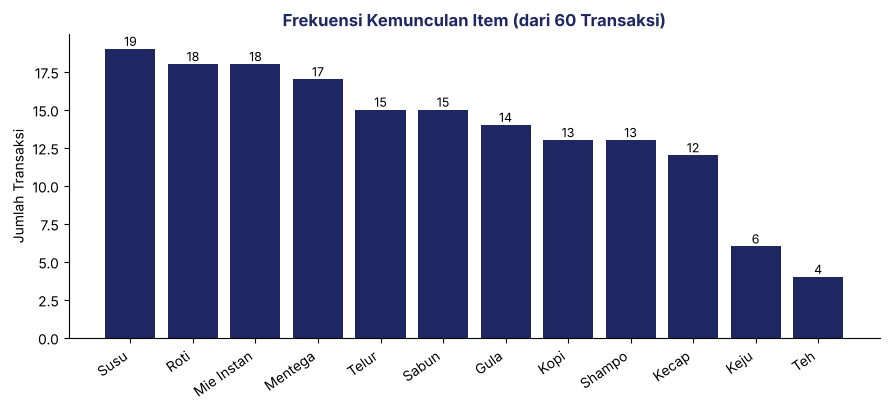

In [3]:
from collections import Counter
cnt = Counter()
for t in transactions:
    cnt.update(t)
for item, freq in cnt.most_common():
    print(f'{item:12s}: {freq:2d}  (support = {freq/len(transactions):.3f})')

# Grafik frekuensi item
items, vals = zip(*cnt.most_common())
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(items, vals, color=NAVY)
ax.bar_label(bars, fontsize=9)
ax.set_ylabel('Jumlah Transaksi')
ax.set_title('Frekuensi Kemunculan Item (dari 60 Transaksi)', fontweight='bold', color=NAVY)
plt.xticks(rotation=35, ha='right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figs/gambar2_frekuensi_item.png', dpi=150)
plt.show()

**Pengamatan.** Susu merupakan item yang paling sering muncul (19 transaksi; support 0,317), disusul Roti dan Mie Instan (masing-masing 18 transaksi; support 0,300). Teh (4 transaksi; 0,067) dan Keju (6 transaksi; 0,100) adalah item yang paling jarang dibeli. Karena support tertinggi hanya 0,317, nilai min_support yang lebih besar dari angka itu akan membuang seluruh item; informasi ini menjadi dasar pemilihan min_support pada langkah berikutnya.

## 4.2 Encoding Data Transaksi ke Format One-Hot

In [4]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print('Ukuran matriks one-hot:', df.shape)
print(df.iloc[:5, :6])

Ukuran matriks one-hot: (60, 12)
    Gula  Kecap   Keju   Kopi  Mentega  Mie Instan
0   True  False  False   True    False       False
1   True  False  False   True    False       False
2  False  False  False  False     True       False
3  False  False  False  False    False        True
4  False  False   True  False    False       False


**Pengamatan.** Hasil encoding berupa matriks berukuran 60 baris × 12 kolom bernilai True/False, dengan kolom diurutkan secara alfabetis. Sebagai contoh, baris ke-1 dan ke-2 (T1 dan T2) bernilai True pada Gula dan Kopi, baris ke-4 (T4) hanya bernilai True pada Mie Instan, dan baris ke-5 (T5) bernilai True pada Keju; item lain pada transaksi tersebut berada di kolom yang tidak ikut ditampilkan.

## 4.3 Mencari Frequent Itemset dengan Algoritma Apriori

In [5]:
MIN_SUP = 0.15
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True)
freq_apriori = freq_apriori.sort_values('support', ascending=False)

print('Jumlah frequent itemset:', len(freq_apriori))
print(freq_apriori.round(3).to_string(index=False))

# Rincian jumlah itemset menurut ukurannya
print()
print('Rincian per ukuran itemset:')
print(freq_apriori['itemsets'].map(len).value_counts().sort_index().rename('jumlah').to_string())

Jumlah frequent itemset: 17
 support                         itemsets
   0.317                frozenset({Susu})
   0.300                frozenset({Roti})
   0.300          frozenset({Mie Instan})
   0.283             frozenset({Mentega})
   0.250               frozenset({Sabun})
   0.250               frozenset({Telur})
   0.233                frozenset({Gula})
   0.217              frozenset({Shampo})
   0.217                frozenset({Kopi})
   0.217          frozenset({Roti, Susu})
   0.217       frozenset({Roti, Mentega})
   0.200               frozenset({Kecap})
   0.183       frozenset({Mentega, Susu})
   0.183 frozenset({Roti, Mentega, Susu})
   0.167   frozenset({Mie Instan, Telur})
   0.150   frozenset({Mie Instan, Kecap})
   0.150       frozenset({Shampo, Sabun})

Rincian per ukuran itemset:
itemsets
1    10
2     6
3     1


**Pengamatan.** Dengan min_support = 0,15 (minimal 9 dari 60 transaksi) ditemukan 17 frequent itemset, terdiri atas 10 itemset satu item, 6 itemset dua item, dan 1 itemset tiga item. Dari 12 item tunggal, 10 lolos ambang batas; hanya Keju dan Teh yang gugur.

Itemset terbesar adalah {Mentega, Roti, Susu} dengan support 0,183 (11 transaksi), yang mengindikasikan adanya pola paket sarapan. Enam pasangan yang frequent berasal dari tiga kelompok: kelompok sarapan ({Roti, Susu}, {Mentega, Roti}, {Mentega, Susu}), kelompok mie instan ({Mie Instan, Telur}, {Kecap, Mie Instan}), dan kelompok mandi ({Sabun, Shampo}). Pasangan {Kopi, Gula} belum muncul karena support-nya (0,133) berada di bawah ambang batas; pasangan ini baru tertangkap pada Tugas 1.

## 4.4 Membentuk Aturan Asosiasi

In [6]:
def fmt(s):
    return ', '.join(sorted(s))

def tabel_aturan(r):
    t = r.copy()
    t['Aturan'] = t['antecedents'].map(fmt) + ' → ' + t['consequents'].map(fmt)
    return t[['Aturan', 'support', 'confidence', 'lift']].round(3)

MIN_CONF = 0.5
rules = association_rules(freq_apriori, metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)
rules.to_csv('rules.csv', index=False)

print('Jumlah aturan asosiasi:', len(rules))
print(tabel_aturan(rules).to_string(index=False))

Jumlah aturan asosiasi: 18
              Aturan  support  confidence  lift
Mentega, Susu → Roti    0.183       1.000 3.333
Roti → Mentega, Susu    0.183       0.611 3.333
Roti, Susu → Mentega    0.183       0.846 2.986
Mentega → Roti, Susu    0.183       0.647 2.986
      Sabun → Shampo    0.150       0.600 2.769
      Shampo → Sabun    0.150       0.692 2.769
Susu → Mentega, Roti    0.183       0.579 2.672
Mentega, Roti → Susu    0.183       0.846 2.672
      Roti → Mentega    0.217       0.722 2.549
      Mentega → Roti    0.217       0.765 2.549
  Mie Instan → Kecap    0.150       0.500 2.500
  Kecap → Mie Instan    0.150       0.750 2.500
         Roti → Susu    0.217       0.722 2.281
         Susu → Roti    0.217       0.684 2.281
  Telur → Mie Instan    0.167       0.667 2.222
  Mie Instan → Telur    0.167       0.556 2.222
      Mentega → Susu    0.183       0.647 2.043
      Susu → Mentega    0.183       0.579 2.043


**Pengamatan.** Dengan min_confidence = 0,5 terbentuk 18 aturan asosiasi. Jumlah ini sama dengan seluruh kandidat aturan yang mungkin dibentuk dari 7 itemset berukuran dua item atau lebih (6 pasangan × 2 arah + 6 pemisahan pada itemset tiga item), sehingga semua kandidat memenuhi ambang confidence 0,5. Seluruh aturan memiliki lift di atas 1 (berkisar 2,043 sampai 3,333), artinya semuanya menunjukkan korelasi positif.

Aturan dengan lift tertinggi adalah {Mentega, Susu} → {Roti} (confidence 1,000; lift 3,333): setiap transaksi yang memuat Mentega dan Susu juga memuat Roti. Seluruh aturan juga disimpan ke berkas rules.csv untuk dipakai pada Tugas 2.

## 4.5 Visualisasi Hasil

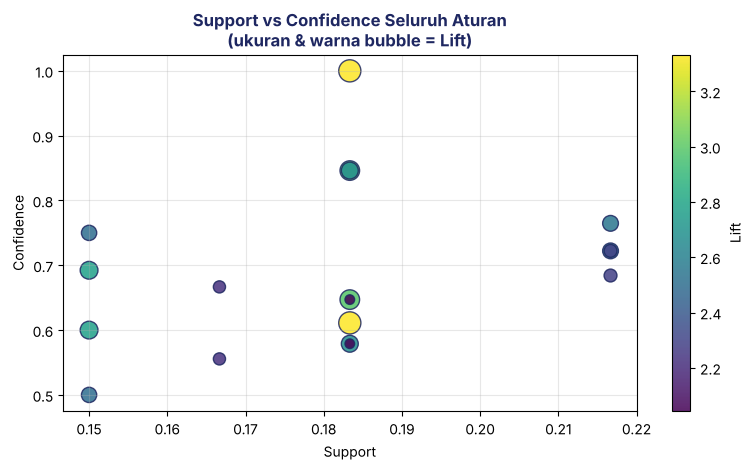

In [7]:
sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
fig, ax = plt.subplots(figsize=(8, 4.8))
sc = ax.scatter(rules['support'], rules['confidence'], s=sizes,
                c=rules['lift'], cmap='viridis', alpha=0.85, edgecolor=NAVY)
plt.colorbar(sc, label='Lift')
ax.set_xlabel('Support'); ax.set_ylabel('Confidence')
ax.set_title('Support vs Confidence Seluruh Aturan\n(ukuran & warna bubble = Lift)',
             fontweight='bold', color=NAVY)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figs/gambar3_scatter_aturan.png', dpi=150)
plt.show()

**Pengamatan.** Pada grafik sebar, titik kuning besar di bagian atas (confidence 1,0) adalah aturan {Mentega, Susu} → {Roti} yang sekaligus memiliki lift tertinggi. Titik-titik pada support terbesar (0,217) berwarna lebih gelap, yaitu lift-nya lebih rendah (2,281 sampai 2,549) dibanding titik pada support 0,183. Dengan demikian, support atau confidence yang tinggi tidak otomatis berarti lift yang tinggi, sehingga ketiga ukuran perlu dibaca bersama.

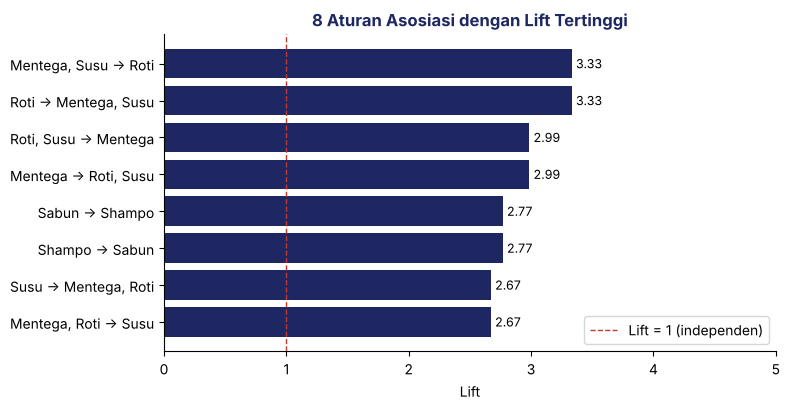

In [8]:
top8 = rules.head(8).iloc[::-1]
labels = top8['antecedents'].map(fmt) + ' → ' + top8['consequents'].map(fmt)
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(labels, top8['lift'], color=NAVY)
ax.bar_label(bars, fmt='%.2f', fontsize=9, padding=3)
ax.axvline(1, color=RED, ls='--', lw=1, label='Lift = 1 (independen)')
ax.set_xlabel('Lift'); ax.set_xlim(0, 5)
ax.set_title('8 Aturan Asosiasi dengan Lift Tertinggi', fontweight='bold', color=NAVY)
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figs/gambar4_lift_tertinggi.png', dpi=150)
plt.show()

**Pengamatan.** Delapan aturan dengan lift tertinggi didominasi kelompok sarapan (Mentega, Roti, Susu) dan satu pasang aturan kelompok mandi (Sabun ↔ Shampo). Semua batang berada jauh di sebelah kanan garis Lift = 1, sehingga kelompok produk tersebut dibeli bersama jauh lebih sering daripada yang diharapkan jika pembeliannya saling bebas.

## 4.6 Interpretasi Bisnis dari Aturan Terpilih

In [9]:
terpilih = [('Mentega, Susu', 'Roti'), ('Sabun', 'Shampo'), ('Kecap', 'Mie Instan')]
for a, c in terpilih:
    baris = rules[(rules['antecedents'].map(fmt) == a) & (rules['consequents'].map(fmt) == c)].iloc[0]
    print(f'{a} → {c}: support={baris.support:.3f}, confidence={baris.confidence:.3f}, lift={baris.lift:.3f}')

Mentega, Susu → Roti: support=0.183, confidence=1.000, lift=3.333
Sabun → Shampo: support=0.150, confidence=0.600, lift=2.769
Kecap → Mie Instan: support=0.150, confidence=0.750, lift=2.500


**Pengamatan.** Tiga aturan dari kelompok berbeda dapat langsung diterjemahkan menjadi tindakan bisnis. Pertama, {Mentega, Susu} → {Roti} (lift 3,333; confidence 100%) mendukung penempatan ketiga produk berdekatan atau penawaran paket "Sarapan Hemat". Kedua, Sabun → Shampo (lift 2,769; confidence 60%) mendukung penataan rak toiletries yang berdekatan dan terpisah dari rak sembako. Ketiga, Kecap → Mie Instan (lift 2,500; confidence 75%) dapat dipakai untuk fitur rekomendasi "pelanggan yang membeli ini juga membeli" pada aplikasi belanja. Aturan asosiasi hanya menunjukkan korelasi, bukan sebab-akibat, sehingga keputusan tetap perlu divalidasi, misalnya dengan A/B testing.

## 4.7 Eksperimen: Pengaruh Nilai min_support

min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan
min_support=0.20: 12 itemset,  4 aturan
min_support=0.25:  6 itemset,  0 aturan
min_support=0.30:  3 itemset,  0 aturan
min_support=0.35:  0 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


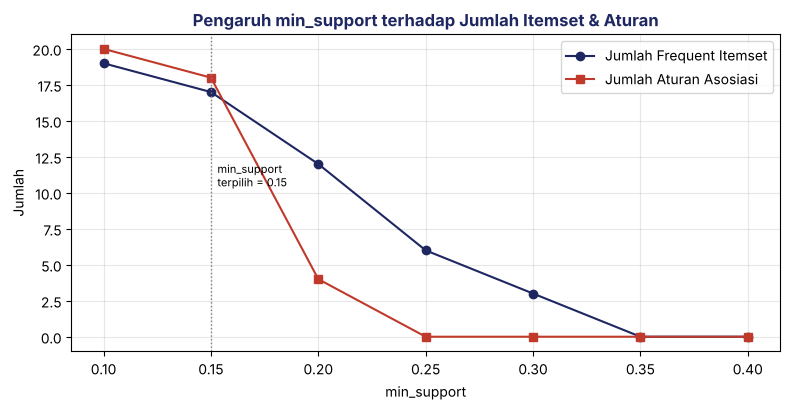

In [10]:
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
n_item, n_rule = [], []
for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = association_rules(fi, metric='confidence', min_threshold=0.5) if len(fi) else pd.DataFrame()
    n_item.append(len(fi)); n_rule.append(len(r))
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sweep_sup, n_item, 'o-', color=NAVY, label='Jumlah Frequent Itemset')
ax.plot(sweep_sup, n_rule, 's-', color=RED, label='Jumlah Aturan Asosiasi')
ax.axvline(0.15, color='gray', ls=':', lw=1)
ax.text(0.153, max(n_item) * 0.55, 'min_support\nterpilih = 0.15', fontsize=8)
ax.set_xlabel('min_support'); ax.set_ylabel('Jumlah')
ax.set_title('Pengaruh min_support terhadap Jumlah Itemset & Aturan', fontweight='bold', color=NAVY)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figs/gambar5_sweep_support.png', dpi=150)
plt.show()

**Pengamatan.** Jumlah itemset turun dari 19 (min_support 0,10) hingga 0 (min_support 0,35 ke atas), sedangkan jumlah aturan turun jauh lebih tajam: pada min_support 0,20 masih tersisa 12 itemset tetapi hanya 4 aturan. Penyebabnya, pada ambang tersebut sebagian besar itemset yang tersisa adalah item tunggal (10 item tunggal dan 2 pasangan) yang tidak dapat dibentuk menjadi aturan X → Y.

Pada min_support 0,25 dan 0,30 masih ada 6 dan 3 itemset, namun semuanya berupa item tunggal sehingga tidak ada aturan. Pada 0,35 ke atas tidak ada lagi itemset karena support tertinggi (Susu) hanya 0,317. Nilai 0,15 dipilih sebagai nilai kerja karena menghasilkan 18 aturan yang cukup kaya untuk dianalisis tanpa mengikutsertakan pasangan yang terlalu jarang muncul.

## 4.8 Eksperimen: Apriori vs FP-Growth

Apriori  : 17 itemset, 2.23 ms
FP-Growth: 17 itemset, 1.67 ms
Itemset identik? True


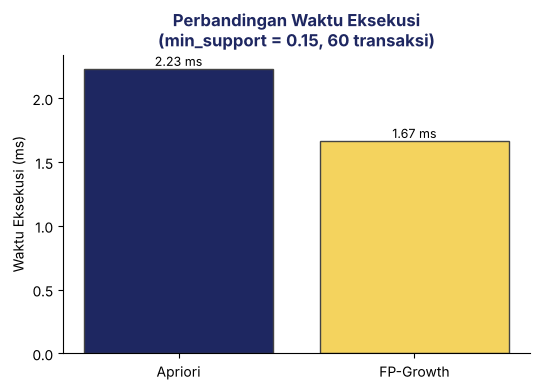

In [11]:
t0 = time.perf_counter()
freq_apriori = apriori(df, min_support=0.15, use_colnames=True)
t_apriori = time.perf_counter() - t0

t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df, min_support=0.15, use_colnames=True)
t_fpgrowth = time.perf_counter() - t0

set_apriori = set(frozenset(s) for s in freq_apriori['itemsets'])
set_fpgrowth = set(frozenset(s) for s in freq_fpgrowth['itemsets'])
print(f'Apriori  : {len(freq_apriori)} itemset, {t_apriori*1000:.2f} ms')
print(f'FP-Growth: {len(freq_fpgrowth)} itemset, {t_fpgrowth*1000:.2f} ms')
print('Itemset identik?', set_apriori == set_fpgrowth)

fig, ax = plt.subplots(figsize=(5.5, 4))
b = ax.bar(['Apriori', 'FP-Growth'], [t_apriori*1000, t_fpgrowth*1000], color=[NAVY, GOLD], edgecolor='#444')
ax.bar_label(b, fmt='%.2f ms', fontsize=9)
ax.set_ylabel('Waktu Eksekusi (ms)')
ax.set_title('Perbandingan Waktu Eksekusi\n(min_support = 0.15, 60 transaksi)', fontweight='bold', color=NAVY)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figs/gambar6_apriori_vs_fpgrowth.png', dpi=150)
plt.show()

**Pengamatan.** Kedua algoritma menghasilkan 17 frequent itemset yang identik (dibandingkan sebagai himpunan sehingga tidak bergantung urutan baris). Hal ini menegaskan bahwa Apriori dan FP-Growth hanya berbeda pada strategi pencarian, bukan pada definisi frequent itemset. Pada eksekusi ini Apriori memerlukan 2,23 ms dan FP-Growth 1,67 ms (FP-Growth sekitar 1,3 kali lebih cepat). Angka waktu tidak sama dengan contoh modul (10,42 ms dan 2,95 ms) karena bergantung pada spesifikasi mesin, versi pustaka, dan beban sistem saat pengukuran; yang konsisten adalah itemset yang dihasilkan dan kecenderungan FP-Growth yang lebih cepat.

# Tugas 1 — Eksplorasi Ambang Batas min_support dan min_confidence

In [12]:
# 1. min_support = 0.10 (min_confidence tetap 0.5), dibandingkan dengan min_support = 0.15
fi_10 = apriori(df, min_support=0.10, use_colnames=True).sort_values('support', ascending=False)
r_10 = association_rules(fi_10, metric='confidence', min_threshold=0.5)
fi_15 = freq_apriori
r_15 = rules

print(f'min_support = 0.10 : {len(fi_10)} itemset, {len(r_10)} aturan')
print(f'min_support = 0.15 : {len(fi_15)} itemset, {len(r_15)} aturan')

baru_item = fi_10[~fi_10['itemsets'].isin(fi_15['itemsets'])]
print('\nItemset tambahan pada min_support = 0.10:')
print(baru_item.round(3).to_string(index=False))

kunci = lambda r: set(zip(r['antecedents'].map(fmt), r['consequents'].map(fmt)))
baru_rule = r_10[[k not in kunci(r_15) for k in zip(r_10['antecedents'].map(fmt), r_10['consequents'].map(fmt))]]
print('\nAturan tambahan pada min_support = 0.10:')
print(tabel_aturan(baru_rule).to_string(index=False))

min_support = 0.10 : 19 itemset, 20 aturan
min_support = 0.15 : 17 itemset, 18 aturan

Itemset tambahan pada min_support = 0.10:
 support                itemsets
   0.133 frozenset({Gula, Kopi})
   0.100       frozenset({Keju})

Aturan tambahan pada min_support = 0.10:
     Aturan  support  confidence  lift
Gula → Kopi    0.133       0.571 2.637
Kopi → Gula    0.133       0.615 2.637


**Analisis.** Menurunkan min_support dari 0,15 menjadi 0,10 menambah frequent itemset dari 17 menjadi 19 dan aturan dari 18 menjadi 20. Ambang 0,10 setara dengan minimal 6 dari 60 transaksi, sedangkan 0,15 setara dengan minimal 9 transaksi.

Dua itemset tambahan adalah {Keju} (support 0,100) dan {Kopi, Gula} (support 0,133). Karena {Keju} hanya berupa item tunggal, ia tidak menghasilkan aturan. Sebaliknya, {Kopi, Gula} menghasilkan dua aturan baru, yaitu Kopi → Gula (confidence 0,615; lift 2,637) dan Gula → Kopi (confidence 0,571; lift 2,637). Lift kedua aturan ini bahkan lebih tinggi daripada aturan Roti → Susu (2,281), tetapi sebelumnya tidak terdeteksi karena pasangan Kopi dan Gula hanya muncul pada 8 transaksi (support 0,133, di bawah 0,15).

Ambang support yang lebih rendah dengan demikian membuka pola dari produk yang lebih jarang dibeli. Imbalannya, pola tersebut didukung oleh lebih sedikit transaksi sehingga lebih rentan terhadap kebetulan.

In [13]:
# 2. Naikkan min_confidence menjadi 0.7 pada min_support = 0.15
lolos = rules[rules['confidence'] >= 0.7]
gugur = rules[rules['confidence'] < 0.7]
print(f'Aturan awal (conf >= 0.5): {len(rules)}')
print(f'Lolos pada conf >= 0.7   : {len(lolos)}')
print(f'Gugur                    : {len(gugur)}')
print('\nAturan yang lolos:')
print(tabel_aturan(lolos).to_string(index=False))
print('\nAturan yang gugur:')
print(tabel_aturan(gugur).to_string(index=False))

Aturan awal (conf >= 0.5): 18
Lolos pada conf >= 0.7   : 7
Gugur                    : 11

Aturan yang lolos:
              Aturan  support  confidence  lift
Mentega, Susu → Roti    0.183       1.000 3.333
Roti, Susu → Mentega    0.183       0.846 2.986
Mentega, Roti → Susu    0.183       0.846 2.672
      Roti → Mentega    0.217       0.722 2.549
      Mentega → Roti    0.217       0.765 2.549
  Kecap → Mie Instan    0.150       0.750 2.500
         Roti → Susu    0.217       0.722 2.281

Aturan yang gugur:
              Aturan  support  confidence  lift
Roti → Mentega, Susu    0.183       0.611 3.333
Mentega → Roti, Susu    0.183       0.647 2.986
      Sabun → Shampo    0.150       0.600 2.769
      Shampo → Sabun    0.150       0.692 2.769
Susu → Mentega, Roti    0.183       0.579 2.672
  Mie Instan → Kecap    0.150       0.500 2.500
         Susu → Roti    0.217       0.684 2.281
  Telur → Mie Instan    0.167       0.667 2.222
  Mie Instan → Telur    0.167       0.556 2.222
      M

**Analisis.** Pada min_confidence 0,7 hanya 7 dari 18 aturan yang lolos, sedangkan 11 aturan gugur. Aturan yang lolos adalah Mentega, Susu → Roti (1,000); Roti, Susu → Mentega (0,846); Mentega, Roti → Susu (0,846); Mentega → Roti (0,765); Kecap → Mie Instan (0,750); Roti → Mentega (0,722); dan Roti → Susu (0,722).

Aturan yang gugur adalah Roti → Mentega, Susu (0,611); Mentega → Roti, Susu (0,647); Susu → Mentega, Roti (0,579); Susu → Roti (0,684); Susu → Mentega (0,579); Mentega → Susu (0,647); Shampo → Sabun (0,692); Sabun → Shampo (0,600); Mie Instan → Kecap (0,500); Telur → Mie Instan (0,667); dan Mie Instan → Telur (0,556).

Terlihat bahwa seluruh aturan dengan Susu sebagai anteseden gugur, begitu pula kedua arah pasangan Sabun–Shampo dan Telur–Mie Instan. Aturan Shampo → Sabun misalnya memiliki lift tinggi (2,769) namun confidence-nya 0,692; lift dapat tinggi karena support Sabun kecil (0,25), meskipun confidence belum mencapai 0,7. Jadi lift dan confidence mengukur hal yang berbeda dan tidak saling menggantikan.

min_confidence=0.5: 18 aturan
min_confidence=0.6: 14 aturan
min_confidence=0.7:  7 aturan
min_confidence=0.8:  3 aturan
min_confidence=0.9:  1 aturan
min_confidence=1.0:  1 aturan


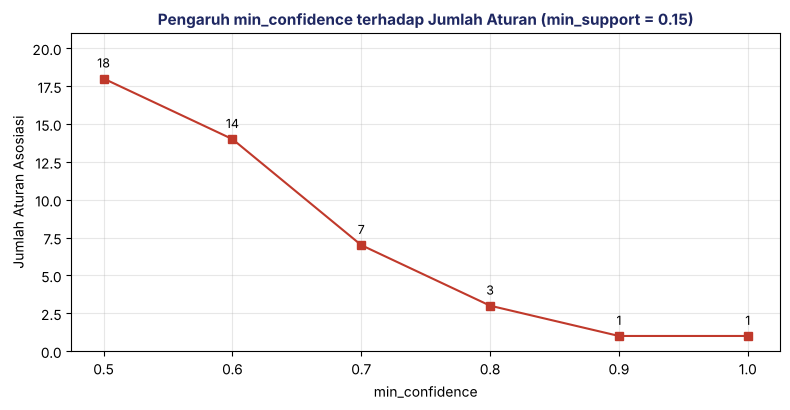

In [14]:
# 3. Sweep min_confidence pada min_support = 0.15
sweep_conf = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
n_rule_conf = []
for c in sweep_conf:
    r = association_rules(freq_apriori, metric='confidence', min_threshold=c)
    n_rule_conf.append(len(r))
    print(f'min_confidence={c:.1f}: {len(r):2d} aturan')

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(sweep_conf, n_rule_conf, 's-', color=RED)
for x, y in zip(sweep_conf, n_rule_conf):
    ax.annotate(str(y), (x, y), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
ax.set_xlabel('min_confidence'); ax.set_ylabel('Jumlah Aturan Asosiasi')
ax.set_title('Pengaruh min_confidence terhadap Jumlah Aturan (min_support = 0.15)',
             fontweight='bold', color=NAVY, fontsize=11)
ax.set_ylim(0, max(n_rule_conf) + 3); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figs/tugas1_sweep_confidence.png', dpi=150)
plt.show()

**Analisis.** Jumlah aturan untuk min_confidence 0,5; 0,6; 0,7; 0,8; 0,9; dan 1,0 berturut-turut adalah 18, 14, 7, 3, 1, dan 1. Penurunan terbesar terjadi antara 0,6 dan 0,7 (14 menjadi 7 aturan), yaitu separuh aturan hilang hanya dengan menaikkan ambang 0,1. Satu-satunya aturan yang bertahan sampai min_confidence 1,0 adalah {Mentega, Susu} → {Roti}: pada 11 transaksi yang memuat Mentega dan Susu (0,183 × 60), Roti selalu ikut dibeli.

Trade-off ambang batas. Ambang rendah (0,5) menghasilkan banyak aturan sehingga cakupan pola luas, tetapi memuat aturan yang lemah, misalnya Mie Instan → Kecap yang hanya benar pada separuh pembeli mie instan, serta banyak aturan yang saling berulang (arah berlawanan dan variasi dari itemset yang sama). Aturan seperti ini berisiko menjadi noise yang mengarahkan keputusan bisnis secara keliru. Ambang tinggi (0,9 sampai 1,0) menghasilkan aturan yang sangat dapat diandalkan, tetapi hanya satu aturan yang tersisa dan pola berguna seperti Sabun → Shampo (0,600) dan Telur → Mie Instan (0,667), yang liftnya di atas 2, ikut terbuang.

Pada dataset ini ambang 0,6 sampai 0,7 merupakan titik kompromi yang masuk akal: pada 0,7 masih ada 7 aturan dari kelompok sarapan dan kelompok kecap–mie instan, tetapi kelompok produk mandi sudah hilang. Pemilihan ambang sebaiknya mengikuti tujuan: eksplorasi pola memakai ambang rendah, sedangkan keputusan yang berbiaya (misalnya paket promo) memakai ambang lebih tinggi dan dikombinasikan dengan lift > 1. Karena datanya hanya 60 transaksi, setiap aturan, termasuk yang ber-confidence tinggi, tetap perlu diperlakukan sebagai hipotesis.

# Tugas 2 — Analisis Mendalam Aturan yang Belum Dibahas

In [15]:
# Dua aturan yang belum dibahas pada Bagian 4.6: Roti → Susu dan Telur → Mie Instan
N = len(df)

def hitung_manual(x, y):
    # support dihitung langsung dari jumlah transaksi
    n_x  = df[x].all(axis=1).sum()
    n_y  = df[y].all(axis=1).sum()
    n_xy = df[x + y].all(axis=1).sum()
    s_x, s_y, s_xy = n_x / N, n_y / N, n_xy / N
    conf = s_xy / s_x
    lift = conf / s_y
    leverage = s_xy - s_x * s_y
    conviction = (1 - s_y) / (1 - conf) if conf < 1 else float('inf')
    return dict(n_x=n_x, n_y=n_y, n_xy=n_xy, s_x=s_x, s_y=s_y, s_xy=s_xy,
                confidence=conf, lift=lift, leverage=leverage, conviction=conviction)

hasil = []
for x, y in [(['Roti'], ['Susu']), (['Telur'], ['Mie Instan'])]:
    m = hitung_manual(x, y)
    print(f"{', '.join(x)} → {', '.join(y)}")
    print(f"  |X|={m['n_x']}, |Y|={m['n_y']}, |X∪Y|={m['n_xy']} dari {N} transaksi")
    print(f"  support(X)={m['s_x']:.4f}, support(Y)={m['s_y']:.4f}, support(X∪Y)={m['s_xy']:.4f}")
    print(f"  confidence = {m['confidence']:.4f}")
    print(f"  lift       = {m['lift']:.4f}")
    print(f"  leverage   = {m['s_xy']:.4f} - ({m['s_x']:.4f} x {m['s_y']:.4f}) = {m['leverage']:.4f}")
    print(f"  conviction = (1 - {m['s_y']:.4f}) / (1 - {m['confidence']:.4f}) = {m['conviction']:.4f}")
    hasil.append(m)

# Verifikasi terhadap keluaran mlxtend
print('\nVerifikasi dengan mlxtend (association_rules):')
cek = rules[((rules['antecedents'].map(fmt) == 'Roti') & (rules['consequents'].map(fmt) == 'Susu')) |
            ((rules['antecedents'].map(fmt) == 'Telur') & (rules['consequents'].map(fmt) == 'Mie Instan'))].copy()
cek['Aturan'] = cek['antecedents'].map(fmt) + ' → ' + cek['consequents'].map(fmt)
print(cek[['Aturan', 'confidence', 'lift', 'leverage', 'conviction']].round(4).to_string(index=False))

Roti → Susu
  |X|=18, |Y|=19, |X∪Y|=13 dari 60 transaksi
  support(X)=0.3000, support(Y)=0.3167, support(X∪Y)=0.2167
  confidence = 0.7222
  lift       = 2.2807
  leverage   = 0.2167 - (0.3000 x 0.3167) = 0.1217
  conviction = (1 - 0.3167) / (1 - 0.7222) = 2.4600
Telur → Mie Instan
  |X|=15, |Y|=18, |X∪Y|=10 dari 60 transaksi
  support(X)=0.2500, support(Y)=0.3000, support(X∪Y)=0.1667
  confidence = 0.6667
  lift       = 2.2222
  leverage   = 0.1667 - (0.2500 x 0.3000) = 0.0917
  conviction = (1 - 0.3000) / (1 - 0.6667) = 2.1000

Verifikasi dengan mlxtend (association_rules):
            Aturan  confidence   lift  leverage  conviction
       Roti → Susu      0.7222 2.2807    0.1217        2.46
Telur → Mie Instan      0.6667 2.2222    0.0917        2.10


**Analisis.** Dua aturan yang dipilih belum dibahas pada Bagian 4.6 dan keduanya tidak melibatkan Mentega: Roti → Susu dan Telur → Mie Instan. Nilai yang dihitung manual dari jumlah transaksi sama persis dengan keluaran mlxtend sehingga perhitungan terverifikasi.

Perbandingan dengan lift. Lift kedua aturan hampir sama (2,281 dan 2,222; selisih sekitar 0,06), sehingga jika hanya melihat lift keduanya tampak setara. Leverage dan conviction memberi gambaran yang lebih rinci. Leverage Roti → Susu adalah 0,1217, yaitu pasangan Roti–Susu muncul sekitar 7,3 transaksi (0,1217 × 60) lebih banyak daripada yang diharapkan jika keduanya independen (13 transaksi teramati dibanding sekitar 5,7 yang diharapkan). Leverage Telur → Mie Instan adalah 0,0917, atau sekitar 5,5 transaksi lebih banyak (10 teramati dibanding sekitar 4,5 yang diharapkan). Jadi lift menilai kekuatan hubungan secara relatif (rasio), sedangkan leverage menilai besarnya dampak dalam jumlah transaksi, dan aturan Roti → Susu berdampak lebih luas karena support-nya lebih besar (0,217 dibanding 0,167).

Conviction Roti → Susu bernilai 2,46 dan Telur → Mie Instan bernilai 2,10. Artinya, jika kedua item saling independen, aturan akan salah sekitar 2,46 kali (dan 2,10 kali) lebih sering daripada yang terjadi pada data; dengan kata lain tingkat kesalahan aturan hanya sekitar 41% (dan 48%) dari yang diharapkan pada kondisi independen. Pada ketiga ukuran, Roti → Susu sedikit lebih kuat, dan selisih ini lebih jelas terlihat pada leverage dan conviction daripada pada lift.

Interpretasi bisnis Roti → Susu. Sekitar 72% pembeli roti juga membeli susu. Toko dapat menempatkan susu kemasan di dekat rak roti, menawarkan paket "Roti + Susu" berharga hemat, atau memberi pengingat di kasir bagi pembeli roti yang belum mengambil susu. Karena Roti juga berpasangan dengan Mentega (confidence 0,722), rak sarapan sebaiknya menyatukan ketiganya.

Interpretasi bisnis Telur → Mie Instan. Sekitar 67% pembeli telur juga membeli mie instan. Pola ini cocok untuk paket "Mie Telur" atau cross-selling di aplikasi dengan pesan "pembeli telur juga membeli mie instan". Telur juga muncul pada transaksi sarapan (misalnya T3 dan T5), sehingga penempatan telur di dua lokasi (rak sarapan dan dekat mie instan) dapat dipertimbangkan. Karena Kecap juga berpasangan dengan Mie Instan (confidence 0,750), kombinasi Mie Instan + Telur + Kecap dapat diuji sebagai paket, tetapi ini masih hipotesis karena kombinasi tiga item tersebut tidak termasuk frequent itemset pada min_support 0,15.

# Tugas 3 — Perbandingan Apriori vs FP-Growth pada Ambang Lebih Rendah

--- Perbandingan utama: min_support = 0.15 vs 0.05 ---


 min_sup  n_apriori  n_fpgrowth  identik  apriori_1x  fpgrowth_1x  apriori_med  fpgrowth_med  rasio
    0.15         17          17     True        1.80         1.05         1.30          0.93   1.40
    0.05         42          42     True        1.61         1.17         1.67          1.13   1.48
(satuan waktu: ms; _1x = satu kali jalan, _med = median 200 kali jalan; rasio = apriori_med / fpgrowth_med)

Rincian itemset pada min_support = 0.05 (per ukuran):
itemsets
1    12
2    21
3     8
4     1

--- Sweep tambahan: median waktu (200 kali jalan) ---


 min_sup  n_itemset  apriori(ms)  fpgrowth(ms)  selisih(ms)  rasio A/F
    0.15         17         1.29          0.96         0.33       1.35
    0.10         19         1.30          0.94         0.35       1.38
    0.07         25         1.32          1.03         0.29       1.29
    0.05         42         1.63          1.10         0.53       1.48
    0.03         68         1.76          1.42         0.34       1.24


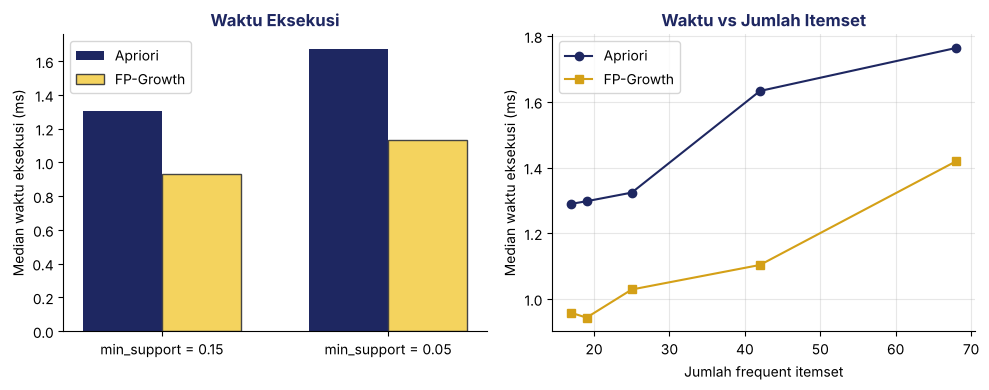

In [16]:
def banding(d, s, ulang=200):
    # Jalankan Apriori dan FP-Growth bergantian; ambil MEDIAN waktu agar tahan terhadap gangguan sesaat
    ta, tf = [], []
    for _ in range(ulang):
        t0 = time.perf_counter(); ha = apriori(d, min_support=s, use_colnames=True); ta.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); hf = fpgrowth(d, min_support=s, use_colnames=True); tf.append(time.perf_counter() - t0)
    return ha, hf, np.median(ta) * 1000, np.median(tf) * 1000

def satu_kali(d, s):
    # satu kali jalan, seperti pada Bagian 4.8 (sensitif terhadap gangguan sesaat)
    t0 = time.perf_counter(); apriori(d, min_support=s, use_colnames=True); a = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); fpgrowth(d, min_support=s, use_colnames=True); f = (time.perf_counter() - t0) * 1000
    return a, f

print('--- Perbandingan utama: min_support = 0.15 vs 0.05 ---')
baris = []
for s in [0.15, 0.05]:
    a1, f1 = satu_kali(df, s)
    ha, hf, am, fm = banding(df, s)
    identik = set(map(frozenset, ha['itemsets'])) == set(map(frozenset, hf['itemsets']))
    baris.append([s, len(ha), len(hf), identik, a1, f1, am, fm, am / fm])
tabel = pd.DataFrame(baris, columns=['min_sup', 'n_apriori', 'n_fpgrowth', 'identik',
                                     'apriori_1x', 'fpgrowth_1x', 'apriori_med', 'fpgrowth_med', 'rasio'])
print(tabel.round(2).to_string(index=False))
print('(satuan waktu: ms; _1x = satu kali jalan, _med = median 200 kali jalan; rasio = apriori_med / fpgrowth_med)')

fa05 = apriori(df, min_support=0.05, use_colnames=True)
print('\nRincian itemset pada min_support = 0.05 (per ukuran):')
print(fa05['itemsets'].map(len).value_counts().sort_index().rename('jumlah').to_string())

print('\n--- Sweep tambahan: median waktu (200 kali jalan) ---')
sw = []
for s in [0.15, 0.10, 0.07, 0.05, 0.03]:
    ha, hf, am, fm = banding(df, s)
    sw.append([s, len(ha), am, fm, am - fm, am / fm])
sw = pd.DataFrame(sw, columns=['min_sup', 'n_itemset', 'apriori(ms)', 'fpgrowth(ms)', 'selisih(ms)', 'rasio A/F'])
print(sw.round(2).to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(2); w = 0.35
axs[0].bar(x - w/2, tabel['apriori_med'], w, color=NAVY, label='Apriori')
axs[0].bar(x + w/2, tabel['fpgrowth_med'], w, color=GOLD, edgecolor='#444', label='FP-Growth')
axs[0].set_xticks(x); axs[0].set_xticklabels(['min_support = 0.15', 'min_support = 0.05'])
axs[0].set_ylabel('Median waktu eksekusi (ms)'); axs[0].legend()
axs[0].set_title('Waktu Eksekusi', fontweight='bold', color=NAVY)
axs[1].plot(sw['n_itemset'], sw['apriori(ms)'], 'o-', color=NAVY, label='Apriori')
axs[1].plot(sw['n_itemset'], sw['fpgrowth(ms)'], 's-', color='#D4A017', label='FP-Growth')
axs[1].set_xlabel('Jumlah frequent itemset'); axs[1].set_ylabel('Median waktu eksekusi (ms)')
axs[1].set_title('Waktu vs Jumlah Itemset', fontweight='bold', color=NAVY)
axs[1].legend(); axs[1].grid(alpha=0.3)
for a in axs: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figs/tugas3_perbandingan_waktu.png', dpi=150)
plt.show()

**Analisis.** Pada min_support 0,05 (minimal 3 dari 60 transaksi) frequent itemset naik dari 17 menjadi 42 (12 item tunggal, 21 pasangan, 8 itemset tiga item, dan 1 itemset empat item). Apriori dan FP-Growth menghasilkan himpunan itemset yang identik pada kedua ambang batas.

Berdasarkan median dari 200 kali eksekusi, pada min_support 0,15 Apriori memerlukan 1,30 ms dan FP-Growth 0,93 ms (rasio 1,40; selisih 0,37 ms), sedangkan pada min_support 0,05 Apriori memerlukan 1,67 ms dan FP-Growth 1,13 ms (rasio 1,48; selisih 0,54 ms). Pengukuran satu kali jalan seperti pada Bagian 4.8 lebih berfluktuasi (Apriori 1,80 ms dan 1,61 ms; FP-Growth 1,05 ms dan 1,17 ms), sehingga median dipakai sebagai dasar perbandingan.

Dengan demikian FP-Growth tetap lebih cepat pada kedua ambang batas dan selisih absolutnya sedikit membesar ketika ambang diturunkan. Namun kecenderungan ini lemah: pada sweep tambahan (min_support 0,15; 0,10; 0,07; 0,05; 0,03) rasio Apriori/FP-Growth bernilai 1,35; 1,38; 1,29; 1,48; dan 1,24, yaitu tidak naik secara konsisten mengikuti jumlah itemset (pada 0,03 dengan 68 itemset rasionya justru turun). Selisih sekitar 0,3 sampai 0,5 ms pada data sekecil ini juga masih dekat dengan biaya tetap pemanggilan fungsi dan pengolahan DataFrame. Karena itu, pernyataan bahwa keunggulan FP-Growth "semakin jelas" pada ambang yang lebih rendah hanya didukung secara lemah oleh data ini.

Alasan secara teori. Semakin rendah min_support, semakin banyak kandidat yang lolos pada setiap level, sehingga Apriori harus membangkitkan dan menghitung support kandidat dalam jumlah yang membesar secara kombinatorial dan memindai data pada setiap level. FP-Growth hanya memindai data dua kali untuk membangun FP-Tree, lalu menambang itemset dari pohon tersebut tanpa membangkitkan kandidat. Keunggulan ini baru terlihat jelas pada data dengan banyak item, transaksi panjang, dan ambang rendah, sedangkan dataset ini hanya memiliki 12 item dan paling banyak 5 item per transaksi sehingga ruang pencariannya kecil.

In [17]:
# Eksperimen tambahan: pengaruh JUMLAH BARIS transaksi (baris dataset digandakan, min_support = 0.05)
# Karena baris hanya digandakan, itemset yang ditemukan sama; yang berubah hanya biaya memindai/memproses data.
sk = []
for k in [1, 10, 100, 500]:
    d = pd.concat([df] * k, ignore_index=True)
    ha, hf, am, fm = banding(d, 0.05, ulang=5)
    sk.append([len(d), len(ha), am, fm, am / fm])
sk = pd.DataFrame(sk, columns=['n_transaksi', 'n_itemset', 'apriori(ms)', 'fpgrowth(ms)', 'rasio A/F'])
print(sk.round(2).to_string(index=False))

 n_transaksi  n_itemset  apriori(ms)  fpgrowth(ms)  rasio A/F
          60         42         1.68          1.29       1.30
         600         42         1.88          2.54       0.74
        6000         42         2.08         11.79       0.18
       30000         42         4.31         52.90       0.08


**Analisis.** Eksperimen tambahan memperlihatkan hal yang penting. Ketika baris dataset digandakan menjadi 600, 6.000, dan 30.000 transaksi (itemset tetap 42), waktu Apriori hanya naik dari 1,68 ms menjadi 4,31 ms, sedangkan FP-Growth naik dari 1,29 ms menjadi 52,90 ms. Pada 600 transaksi ke atas FP-Growth justru lebih lambat (rasio Apriori/FP-Growth 0,74; 0,18; dan 0,08). Pengulangan pada eksperimen ini hanya 5 kali, sehingga angka pada 60 transaksi kurang stabil dibanding tabel utama.

Dugaan penulis, hasil ini berkaitan dengan implementasi di mlxtend: pembangunan FP-Tree dilakukan dengan kode Python murni yang biaya per transaksinya besar, sedangkan Apriori memanfaatkan operasi vektor pada matriks one-hot; dugaan ini tidak diuji lebih lanjut pada praktikum ini. Pelajarannya, keunggulan FP-Growth yang dijelaskan secara teori tidak otomatis berlaku pada setiap implementasi dan setiap bentuk data, sehingga pemilihan algoritma sebaiknya diuji pada data yang sebenarnya.

# Tugas 4 — Studi Kasus Mandiri: Kedai Kopi

Dataset studi kasus dibuat secara sintetis (50 transaksi, 10 jenis item) untuk sebuah kedai kopi, dengan pola
pembelian bersama yang disengaja (mis. kopi + roti, minuman teh + camilan gorengan). Data dibangkitkan dengan
`random.Random(2026)` sehingga hasilnya dapat direproduksi, lalu disimpan sebagai `transactions_kedai_kopi.csv`.

In [18]:
import random

def bangun_transaksi_kedai_kopi(seed=2026, n=50):
    rnd = random.Random(seed)
    items = ['Americano', 'Latte', 'Cappuccino', 'Teh Tarik', 'Croissant',
             'Roti Bakar', 'Kentang Goreng', 'Donat', 'Brownies', 'Air Mineral']
    # (item inti, {item opsional: peluang}, bobot)
    paket = [
        (['Latte', 'Croissant'],         {'Air Mineral': 0.25}, 9),
        (['Americano', 'Roti Bakar'],    {'Air Mineral': 0.30}, 7),
        (['Cappuccino', 'Brownies'],     {'Donat': 0.20},       8),
        (['Teh Tarik', 'Kentang Goreng'], {'Donat': 0.35},      7),
        (['Americano'], {}, 3), (['Latte'], {}, 3), (['Teh Tarik'], {}, 2),
        (['Cappuccino'], {}, 2), (['Donat'], {}, 2),
        (['Brownies', 'Air Mineral'], {}, 2), (['Roti Bakar'], {}, 1),
    ]
    bobot = [p[2] for p in paket]
    hasil = []
    for _ in range(n):
        inti, opsi, _w = rnd.choices(paket, weights=bobot)[0]
        t = list(inti)
        for k, p in opsi.items():
            if rnd.random() < p:
                t.append(k)
        if rnd.random() < 0.12:                 # noise: satu item acak tambahan
            ekstra = rnd.choice(items)
            if ekstra not in t:
                t.append(ekstra)
        hasil.append(sorted(t, key=items.index))
    return hasil

trx4 = bangun_transaksi_kedai_kopi()
pd.DataFrame({'TID': [f'K{i}' for i in range(1, len(trx4) + 1)],
              'Items': [', '.join(t) for t in trx4]}).to_csv('transactions_kedai_kopi.csv', index=False)

print('Jumlah transaksi :', len(trx4))
print('Jumlah jenis item:', len({i for t in trx4 for i in t}))
for i, t in enumerate(trx4[:5], 1):
    print(f'K{i}: {t}')

Jumlah transaksi : 50
Jumlah jenis item: 10
K1: ['Latte', 'Croissant']
K2: ['Cappuccino', 'Teh Tarik']
K3: ['Donat']
K4: ['Cappuccino', 'Brownies']
K5: ['Latte']


**Analisis.** Dataset studi kasus adalah transaksi sebuah kedai kopi yang dibangkitkan secara sintetis: 50 transaksi, 10 jenis item (Americano, Latte, Cappuccino, Teh Tarik, Croissant, Roti Bakar, Kentang Goreng, Donat, Brownies, Air Mineral), dan 1 sampai 3 item per transaksi (rata-rata 1,96). Data dibuat dari empat pola paket (Latte + Croissant, Americano + Roti Bakar, Cappuccino + Brownies, Teh Tarik + Kentang Goreng), beberapa pembelian tunggal, dan noise berupa satu item acak tambahan dengan peluang 12%, memakai seed 2026 sehingga dapat direproduksi. Karena sintetis, pola yang ditemukan mencerminkan pola yang disisipkan pada data dan bukan perilaku pelanggan nyata. Data tersimpan pada transactions_kedai_kopi.csv.

Ukuran matriks one-hot: (50, 10)
Brownies       : 18  (support = 0.360)
Cappuccino     : 17  (support = 0.340)
Latte          : 11  (support = 0.220)
Americano      : 11  (support = 0.220)
Croissant      :  8  (support = 0.160)
Roti Bakar     :  8  (support = 0.160)
Donat          :  7  (support = 0.140)
Air Mineral    :  7  (support = 0.140)
Teh Tarik      :  6  (support = 0.120)
Kentang Goreng :  5  (support = 0.100)


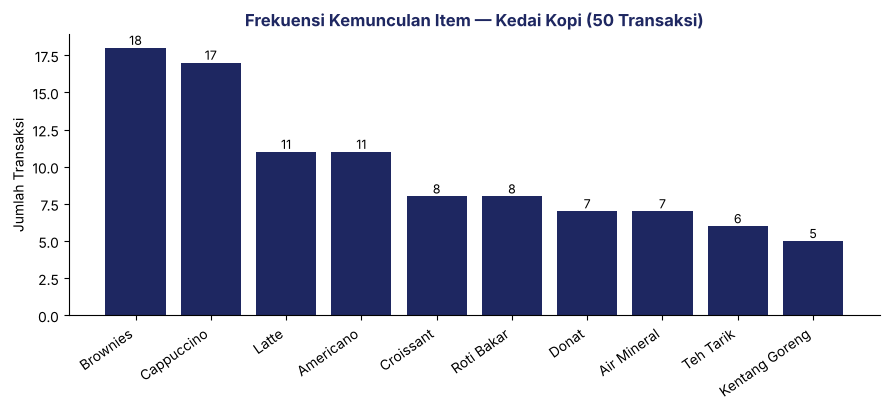

In [19]:
# Encoding one-hot dan frekuensi item
te4 = TransactionEncoder()
df4 = pd.DataFrame(te4.fit(trx4).transform(trx4), columns=te4.columns_)
print('Ukuran matriks one-hot:', df4.shape)

cnt4 = Counter()
for t in trx4:
    cnt4.update(t)
for item, f in cnt4.most_common():
    print(f'{item:15s}: {f:2d}  (support = {f/len(trx4):.3f})')

it4, v4 = zip(*cnt4.most_common())
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(it4, v4, color=NAVY)
ax.bar_label(bars, fontsize=9)
ax.set_ylabel('Jumlah Transaksi')
ax.set_title('Frekuensi Kemunculan Item — Kedai Kopi (50 Transaksi)', fontweight='bold', color=NAVY)
plt.xticks(rotation=35, ha='right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figs/tugas4_frekuensi_item.png', dpi=150)
plt.show()

**Analisis.** Brownies (18 transaksi; support 0,360) dan Cappuccino (17 transaksi; 0,340) adalah item terpopuler, sedangkan Kentang Goreng (5 transaksi; 0,100) dan Teh Tarik (6 transaksi; 0,120) paling jarang. Seluruh item memiliki support minimal 0,10, sehingga ambang min_support 0,10 mempertahankan semua item pada tahap 1-itemset.

In [20]:
# Menentukan ambang batas: telusuri beberapa nilai min_support (min_confidence = 0.6)
for s in [0.05, 0.08, 0.10, 0.12, 0.15, 0.20]:
    fi = apriori(df4, min_support=s, use_colnames=True)
    r = association_rules(fi, metric='confidence', min_threshold=0.6) if len(fi) else []
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan (min_confidence=0.6)')

min_support=0.05: 20 itemset, 12 aturan (min_confidence=0.6)
min_support=0.08: 17 itemset, 10 aturan (min_confidence=0.6)
min_support=0.10: 14 itemset,  8 aturan (min_confidence=0.6)
min_support=0.12: 12 itemset,  6 aturan (min_confidence=0.6)
min_support=0.15:  7 itemset,  2 aturan (min_confidence=0.6)
min_support=0.20:  5 itemset,  2 aturan (min_confidence=0.6)


**Analisis.** Penentuan ambang batas. min_support yang dipilih adalah 0,10 (minimal 5 dari 50 transaksi) dan min_confidence 0,6. Pada min_support 0,15 hanya tersisa 2 aturan karena kelompok yang support-nya 0,14 (Americano–Roti Bakar dan Latte–Croissant) ikut terbuang; pada 0,10 keempat kelompok pasangan muncul (8 aturan). Menurunkan ke 0,08 dan 0,05 hanya menambah aturan (10 dan 12 aturan) yang didukung oleh sangat sedikit transaksi (minimal 4 dan 3 dari 50), sehingga lebih berisiko menjadi kebetulan. min_confidence dinaikkan ke 0,6 (lebih tinggi dari 0,5 pada praktikum) karena datanya kecil, sehingga aturan yang dipakai sebaiknya benar pada setidaknya 60% transaksi yang memuat antesedennya.

In [21]:
MIN_SUP4, MIN_CONF4 = 0.10, 0.6          # minimal 5 dari 50 transaksi; confidence minimal 60%
freq4 = apriori(df4, min_support=MIN_SUP4, use_colnames=True).sort_values('support', ascending=False)
rules4 = association_rules(freq4, metric='confidence', min_threshold=MIN_CONF4)
rules4 = rules4.sort_values('lift', ascending=False).reset_index(drop=True)

print('Jumlah frequent itemset:', len(freq4))
print(freq4.round(3).to_string(index=False))
print('\nJumlah aturan asosiasi :', len(rules4))
t4 = tabel_aturan(rules4)
t4['leverage'] = rules4['leverage'].round(3)
print(t4.to_string(index=False))

Jumlah frequent itemset: 14
 support                               itemsets
    0.36                  frozenset({Brownies})
    0.34                frozenset({Cappuccino})
    0.28      frozenset({Brownies, Cappuccino})
    0.22                 frozenset({Americano})
    0.22                     frozenset({Latte})
    0.16                 frozenset({Croissant})
    0.16                frozenset({Roti Bakar})
    0.14               frozenset({Air Mineral})
    0.14                     frozenset({Donat})
    0.14     frozenset({Roti Bakar, Americano})
    0.14          frozenset({Latte, Croissant})
    0.12                 frozenset({Teh Tarik})
    0.10            frozenset({Kentang Goreng})
    0.10 frozenset({Kentang Goreng, Teh Tarik})

Jumlah aturan asosiasi : 8
                    Aturan  support  confidence  lift  leverage
Kentang Goreng → Teh Tarik     0.10       1.000 8.333     0.088
Teh Tarik → Kentang Goreng     0.10       0.833 8.333     0.088
    Americano → Roti Bakar     0

**Analisis.** Dengan min_support 0,10 dan min_confidence 0,6 ditemukan 14 frequent itemset (10 item tunggal dan 4 pasangan) dan 8 aturan, yang terdiri atas 4 pasangan item dalam dua arah. Aturan dengan lift tertinggi adalah Kentang Goreng → Teh Tarik (confidence 1,000; lift 8,333) dan Teh Tarik → Kentang Goreng (confidence 0,833; lift 8,333), disusul Roti Bakar ↔ Americano dan Croissant ↔ Latte (lift 3,977), serta Cappuccino ↔ Brownies (lift 2,288). Semua aturan memiliki leverage positif (0,088 sampai 0,158).

Lift tertinggi pada Teh Tarik–Kentang Goreng dipengaruhi oleh kedua item yang jarang (support 0,12 dan 0,10) dan pasangannya hanya muncul pada 5 transaksi, sehingga bukti statistiknya lebih lemah dibanding Cappuccino–Brownies yang muncul pada 14 transaksi (support 0,28) meskipun liftnya lebih rendah.

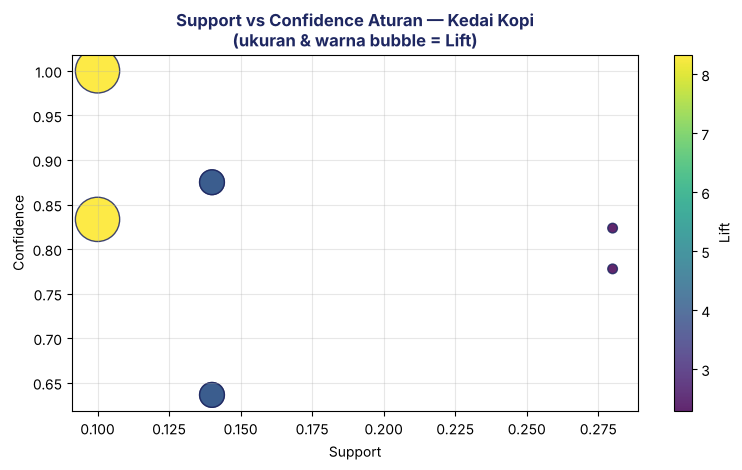

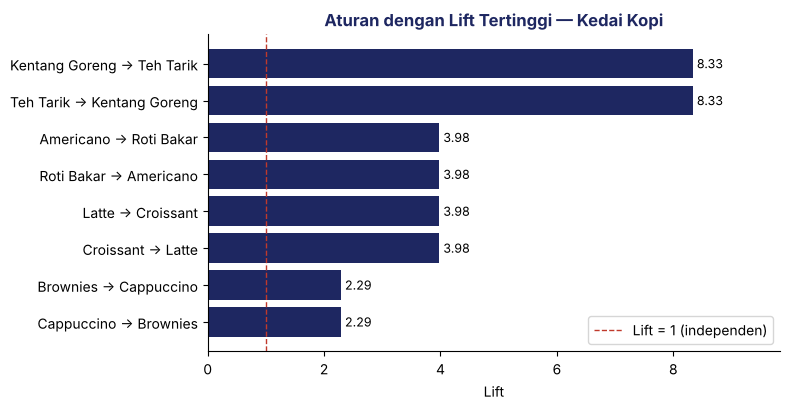

In [22]:
# Scatter plot Support vs Confidence
sizes4 = (rules4['lift'] - rules4['lift'].min() + 0.3) * 160
fig, ax = plt.subplots(figsize=(8, 4.8))
sc = ax.scatter(rules4['support'], rules4['confidence'], s=sizes4, c=rules4['lift'],
                cmap='viridis', alpha=0.85, edgecolor=NAVY)
plt.colorbar(sc, label='Lift')
ax.set_xlabel('Support'); ax.set_ylabel('Confidence')
ax.set_title('Support vs Confidence Aturan — Kedai Kopi\n(ukuran & warna bubble = Lift)',
             fontweight='bold', color=NAVY)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figs/tugas4_scatter.png', dpi=150)
plt.show()

# Bar chart aturan dengan Lift tertinggi
top = rules4.head(8).iloc[::-1]
lab = top['antecedents'].map(fmt) + ' → ' + top['consequents'].map(fmt)
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(lab, top['lift'], color=NAVY)
ax.bar_label(bars, fmt='%.2f', fontsize=9, padding=3)
ax.axvline(1, color=RED, ls='--', lw=1, label='Lift = 1 (independen)')
ax.set_xlabel('Lift'); ax.set_xlim(0, top['lift'].max() + 1.5)
ax.set_title('Aturan dengan Lift Tertinggi — Kedai Kopi', fontweight='bold', color=NAVY)
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figs/tugas4_lift_tertinggi.png', dpi=150)
plt.show()

**Analisis.** Pada grafik sebar, dua titik terbesar berwarna kuning berada di support 0,10 (aturan Teh Tarik ↔ Kentang Goreng), dua titik berwarna biru di support 0,14 (Americano ↔ Roti Bakar dan Croissant ↔ Latte), dan titik-titik berwarna ungu paling kanan di support 0,28 (Cappuccino ↔ Brownies). Pola ini memperlihatkan kebalikan antara support dan lift: pasangan yang paling sering dibeli (support tertinggi) memiliki lift terendah, sedangkan pasangan yang jarang dibeli memiliki lift tertinggi. Bar chart menegaskan urutan lift tersebut.

**Rekomendasi bisnis.** Rekomendasi bisnis berdasarkan aturan dengan lift tertinggi disajikan pada tabel berikut. Seluruh rekomendasi bersifat hipotesis yang perlu divalidasi melalui uji coba, misalnya A/B testing, karena aturan asosiasi hanya menunjukkan korelasi.

| Aturan | Rekomendasi |
|---|---|
| Teh Tarik ↔ Kentang Goreng (lift 8,333; conf. 0,833 dan 1,000) | Buat paket camilan "Teh Tarik + Kentang Goreng" dengan harga paket. Kasir menawarkan kentang goreng kepada pemesan teh tarik karena 83% pemesan teh tarik juga memesannya. Pola ini hanya didukung 5 transaksi sehingga uji coba kecil dulu. |
| Latte ↔ Croissant (lift 3,977; conf. 0,636 dan 0,875) | Buat paket sarapan "Latte + Croissant". Kasir menawarkan latte kepada pemesan croissant (87,5%), dan etalase pastry ditempatkan di dekat mesin kopi atau kasir sehingga mudah terlihat. |
| Americano ↔ Roti Bakar (lift 3,977; conf. 0,636 dan 0,875) | Tawarkan paket "Americano + Roti Bakar" pada jam pagi. Pemesan roti bakar yang belum memesan kopi (87,5% kemungkinan memesan americano) diberi penawaran paket sehingga nilai transaksi rata-rata meningkat. |
| Cappuccino ↔ Brownies (lift 2,288; conf. 0,824 dan 0,778) | Pasangan ini paling sering muncul (28% transaksi), sehingga paket "Ngopi Manis" berpotensi memberi dampak terbesar pada omzet. Tampilkan brownies di dekat mesin espresso dan tampilkan saran "sering dipesan bersama" pada menu digital. |


## Kesimpulan

- Pada dataset 60 transaksi (min_support 0,15; min_confidence 0,5) ditemukan 17 frequent itemset dan 18 aturan asosiasi. Aturan dengan lift tertinggi adalah {Mentega, Susu} → {Roti} (lift 3,333; confidence 1,000).
- Kenaikan min_support dan min_confidence mengurangi jumlah aturan secara tajam (min_support 0,15 → 0,20: 18 → 4 aturan; min_confidence 0,5 → 0,7: 18 → 7 aturan). Penurunan min_support ke 0,10 memunculkan pasangan Kopi–Gula (lift 2,637).
- Apriori dan FP-Growth selalu menghasilkan itemset yang identik. Pada data kecil ini FP-Growth sekitar 1,3–1,5 kali lebih cepat, tetapi pada eksperimen tambahan dengan jumlah baris besar FP-Growth versi mlxtend justru lebih lambat.
- Pada studi kasus kedai kopi (sintetis), pasangan Teh Tarik–Kentang Goreng, Latte–Croissant, Americano–Roti Bakar, dan Cappuccino–Brownies menghasilkan rekomendasi paket dan penataan produk. Aturan asosiasi menunjukkan korelasi, bukan sebab-akibat.